# Distancia caminando: la eikonal y Fast Marching

Este notebook es aparte de `TT.ipynb`; la primera celda copia de ahí el recinto, las salidas, los módulos y `campo()`.

Todo el TT se para en una sola pieza: **¿qué tan lejos está cada celda de algo, caminando?**
- $f_1$ la usa para medir la distancia de cada celda a cada módulo (una eikonal por módulo).
- $f_2$ la usa para saber hacia dónde va la gente (una eikonal por cada recálculo de $T$).

Aquí se compara contra las dos alternativas obvias: la **línea recta** y **Dijkstra** sobre la rejilla.

In [1]:
# ---------- lo mismo que en TT.ipynb: recinto, salidas, módulos y campo() ----------
import numpy as np
import matplotlib.pyplot as plt
import skfmm
from enum import Enum
from dataclasses import dataclass

def pintar(mascara, x, y, ancho, fondo):
    mascara[y:y + fondo, x:x + ancho] = True

def abrir(mascara, x, y, ancho, fondo):
    mascara[y:y + fondo, x:x + ancho] = False

W, H = 200, 120
muros = np.zeros((H, W), dtype=bool)
pintar(muros, 0, 12, W, 1)
for x in (20, 60, 120, 170):
    abrir(muros, x, 12, 8, 1)
pintar(muros, 80, 4, 30, 2)
pintar(muros, 110, 13, 1, H - 13)
abrir(muros, 110, 40, 1, 6)
abrir(muros, 110, 85, 1, 6)
for x in range(12, 110, 12):
    for y in range(25, H, 12):
        pintar(muros, x, y, 1, 1)
pintar(muros, 0, 95, 25, 1)
pintar(muros, 25, 95, 1, H - 95)
abrir(muros, 10, 95, 2, 1)
pintar(muros, 130, 105, 50, 15)
pintar(muros, 194, 40, 6, 20)

SALIDAS = [(30, 0, 10, 1), (140, 0, 10, 1), (0, 50, 1, 6),       # (x, y, ancho, fondo)
           (60, H - 1, 6, 1), (W - 1, 70, 1, 6), (185, H - 1, 6, 1)]
salidas = np.zeros((H, W), dtype=bool)
for s in SALIDAS:
    pintar(salidas, *s)

class Tipo(Enum):
    #                     nombre              ancho fondo  color     unidades  puerta
    SANITARIO         = ("Sanitarios",          8,   3,  "#4C9BE8",  8,      (0, 8))
    COMIDA            = ("Comida",              5,   5,  "#E8A33D",  4,      (1, 4))
    BEBIDAS           = ("Bebidas",             8,   3,  "#7BC96F",  6,      (0, 8))
    PRIMEROS_AUXILIOS = ("Primeros auxilios",   5,   5,  "#A96BE0",  2,      (2, 3))

    def __init__(self, nombre, ancho, fondo, color, unidades, puerta):
        self.nombre = nombre
        self.ancho = ancho
        self.fondo = fondo
        self.color = color
        self.unidades = unidades
        self.puerta = puerta

@dataclass
class Modulo:
    tipo: Tipo
    x: int
    y: int
    rot: int = 0

    @property
    def ancho(self):
        return self.tipo.ancho if self.rot in (0, 180) else self.tipo.fondo

    @property
    def fondo(self):
        return self.tipo.fondo if self.rot in (0, 180) else self.tipo.ancho

    def celdas_puerta(self):
        a, b = self.tipo.puerta
        x, y, w, f = self.x, self.y, self.ancho, self.fondo
        if self.rot == 0:
            return [(x + u, y - 1) for u in range(a, b)]
        if self.rot == 90:
            return [(x + w, y + u) for u in range(a, b)]
        if self.rot == 180:
            return [(x + w - 1 - u, y + f) for u in range(a, b)]
        if self.rot == 270:
            return [(x - 1, y + f - 1 - u) for u in range(a, b)]

layout = [
    Modulo(Tipo.SANITARIO, 14, 28, 0),
    Modulo(Tipo.SANITARIO, 62, 28, 180),
    Modulo(Tipo.SANITARIO, 150, 30, 0),
    Modulo(Tipo.COMIDA, 38, 64, 90),
    Modulo(Tipo.COMIDA, 86, 64, 270),
    Modulo(Tipo.COMIDA, 140, 70, 0),
    Modulo(Tipo.BEBIDAS, 50, 100, 0),
    Modulo(Tipo.BEBIDAS, 160, 95, 180),
    Modulo(Tipo.PRIMEROS_AUXILIOS, 74, 40, 90),
]

def campo(destino, bloqueado, v=None):
    if v is None:
        v = np.ones((H, W))
    phi = np.ones((H, W))
    phi[destino] = -1
    phi = np.ma.MaskedArray(phi, mask=bloqueado)
    v = np.ma.MaskedArray(np.maximum(v, 1e-3), mask=bloqueado)
    return np.ma.filled(skfmm.travel_time(phi, v, dx=1), np.inf)

def bloqueo(layout):
    """Muros + lo que ocupan los módulos."""
    b = muros.copy()
    for m in layout:
        pintar(b, m.x, m.y, m.ancho, m.fondo)
    return b

ocupado = bloqueo(layout)

In [2]:
from scipy import ndimage, sparse
from scipy.sparse.csgraph import dijkstra
from matplotlib.colors import ListedColormap

def capa(ax, M, color, alfa=1.0):
    ax.imshow(np.where(M, 1.0, np.nan), origin="lower", extent=(0, W, 0, H), cmap=ListedColormap([color]),
              alpha=alfa, vmin=0, vmax=1)

def mapa_distancia(ax, D, titulo, vmax=None):
    im = ax.imshow(np.where(np.isfinite(D), D, np.nan), origin="lower", extent=(0, W, 0, H),
                   cmap="viridis", vmin=0, vmax=vmax)
    ax.contour(np.arange(W) + 0.5, np.arange(H) + 0.5, np.where(np.isfinite(D), D, np.nan),
               levels=np.arange(10, 200, 10), colors="white", linewidths=0.5)
    capa(ax, muros, "black")
    capa(ax, salidas, "red")
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])
    return im

## 1. Línea recta contra caminando

La línea recta (`distance_transform_edt`) ignora los muros. La eikonal con $v = 1$ (`campo`) mide lo que de verdad se camina.

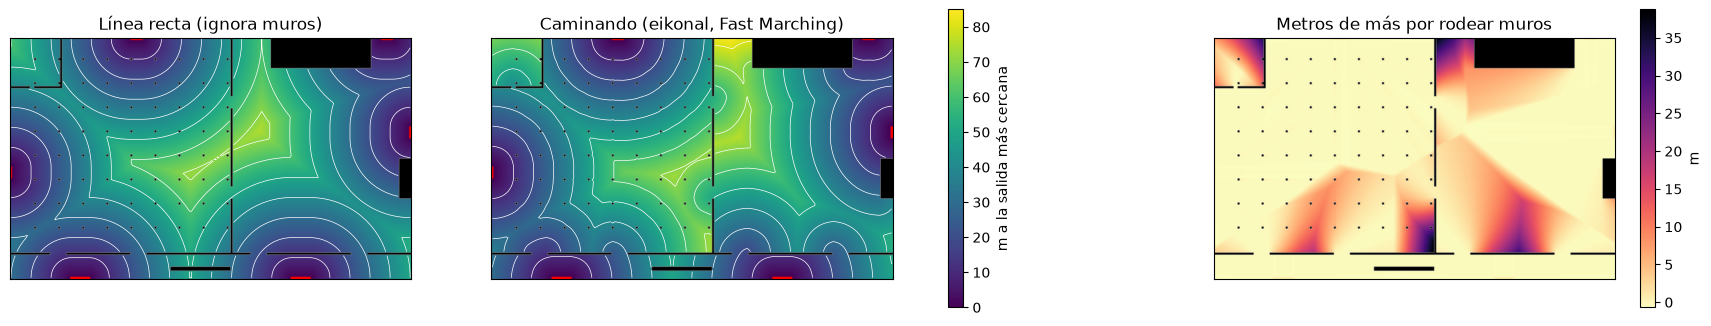

punto más lejano: 74.7 m en línea recta, 84.3 m caminando
lo más que hay que rodear: 38.8 m de más


In [3]:
E = ndimage.distance_transform_edt(~salidas)      # metros en línea recta a la salida más cercana
E[muros] = np.inf
D = campo(salidas, muros)                         # metros caminando (Fast Marching)

fig, ax = plt.subplots(1, 3, figsize=(22, 4.3))
im = mapa_distancia(ax[0], E, "Línea recta (ignora muros)", vmax=85)
mapa_distancia(ax[1], D, "Caminando (eikonal, Fast Marching)", vmax=85)
fig.colorbar(im, ax=ax[:2], shrink=0.9, label="m a la salida más cercana")
extra = np.full((H, W), np.nan)
ok = np.isfinite(D)
extra[ok] = D[ok] - E[ok]
im2 = ax[2].imshow(extra, origin="lower", extent=(0, W, 0, H), cmap="magma_r")
capa(ax[2], muros, "black")
ax[2].set_title("Metros de más por rodear muros"); ax[2].set_xticks([]); ax[2].set_yticks([])
fig.colorbar(im2, ax=ax[2], shrink=0.9, label="m")
plt.show()
print("punto más lejano: %.1f m en línea recta, %.1f m caminando" % (E[np.isfinite(E)].max(), D[np.isfinite(D)].max()))
print("lo más que hay que rodear: %.1f m de más" % np.nanmax(extra))

**Qué ver:** en línea recta, la bodega parece estar junto a la salida oeste; caminando hay que salir por su puerta de 2 m y dar la vuelta. Con la línea recta, un layout que obliga a rodear se vería igual de bueno que uno que no.

## 2. ¿Por qué no Dijkstra?

Dijkstra sobre la rejilla solo puede moverse a las vecinas: con **4 vecinas** mide "en escuadra" (como taxi en cuadras) y con **8 vecinas** solo conoce 8 direcciones. Fast Marching resuelve la eikonal $\|\nabla u\| = 1$, que no tiene direcciones preferidas.

Prueba en un cuarto vacío con una sola fuente en medio: la distancia real son círculos.

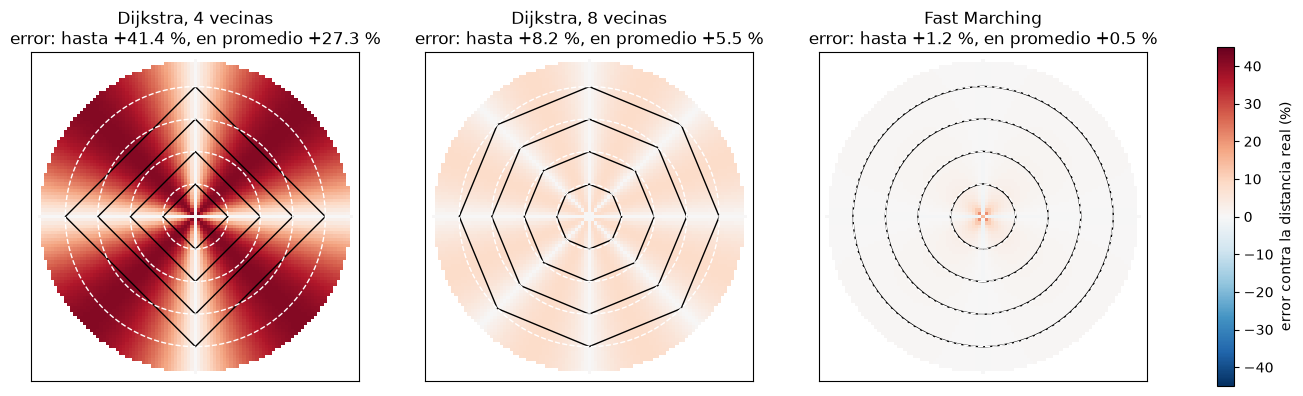

In [4]:
def grafo(libre, vecinos):
    """La rejilla como grafo: cada celda libre es un nodo, unido a sus vecinas libres."""
    h, w = libre.shape
    idx = -np.ones((h, w), dtype=int)
    idx[libre] = np.arange(libre.sum())
    pasos = [(0, 1, 1.0), (1, 0, 1.0)]
    if vecinos == 8:
        pasos += [(1, 1, np.sqrt(2)), (1, -1, np.sqrt(2))]
    filas, cols, pesos = [], [], []
    for dy, dx, costo in pasos:
        a = idx[max(0, -dy):h - max(0, dy), max(0, -dx):w - max(0, dx)]
        b = idx[max(0, dy):h - max(0, -dy), max(0, dx):w - max(0, -dx)]
        ok = (a >= 0) & (b >= 0)
        filas.append(a[ok]); cols.append(b[ok]); pesos.append(np.full(ok.sum(), costo))
    n = int(libre.sum())
    return sparse.coo_matrix((np.concatenate(pesos), (np.concatenate(filas), np.concatenate(cols))),
                             shape=(n, n)).tocsr(), idx

def dist_dijkstra(libre, fuente, vecinos):
    G, idx = grafo(libre, vecinos)
    d = dijkstra(G, directed=False, indices=idx[fuente], min_only=True)
    out = np.full(libre.shape, np.inf)
    out[libre] = d
    return out

n, c = 101, 50
libre_c = np.ones((n, n), dtype=bool)
fuente = np.zeros((n, n), dtype=bool); fuente[c, c] = True
yy, xx = np.mgrid[0:n, 0:n]
real = np.hypot(yy - c, xx - c)                                  # la distancia de verdad
phi = np.where(fuente, -1.0, 1.0)
fmm = skfmm.distance(phi, dx=1) + 0.5                            # +0.5: FMM mide desde la orilla de la celda fuente
metodos = {"Dijkstra, 4 vecinas": dist_dijkstra(libre_c, fuente, 4),
           "Dijkstra, 8 vecinas": dist_dijkstra(libre_c, fuente, 8),
           "Fast Marching": fmm}

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
lejos = (real >= 20) & (real <= 45)
for a, (nombre, d) in zip(ax, metodos.items()):
    err = 100 * (d - real) / np.maximum(real, 1)
    im = a.imshow(np.where(real <= 48, err, np.nan), origin="lower", cmap="RdBu_r", vmin=-45, vmax=45)
    a.contour(d, levels=[10, 20, 30, 40], colors="black", linewidths=1)
    a.contour(real, levels=[10, 20, 30, 40], colors="white", linewidths=1, linestyles="--")
    a.set_title("%s\nerror: hasta %+.1f %%, en promedio %+.1f %%" % (nombre, err[lejos].max(), err[lejos].mean()))
    a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=ax, shrink=0.8, label="error contra la distancia real (%)")
plt.show()

**Qué ver:** en negro, las curvas de 10, 20, 30 y 40 m de cada método; en blanco punteado, los círculos reales. Con 4 vecinas salen **rombos** (las diagonales cuestan hasta 41 % de más) y con 8 vecinas **octágonos** (hasta 8 %). Fast Marching sigue a los círculos.

El error de Dijkstra depende de la **dirección**: dos módulos a la misma distancia real quedan a distancias distintas según si están en diagonal o alineados con la rejilla. Eso le metería a $f_1$ un sesgo que no tiene nada que ver con el layout.

## 3. En el recinto: rutas y distancias

Ahora con muros. La ruta de Fast Marching se obtiene bajando por el gradiente de $D$ (como la canica, pero en continuo); la de Dijkstra, siguiendo los predecesores.

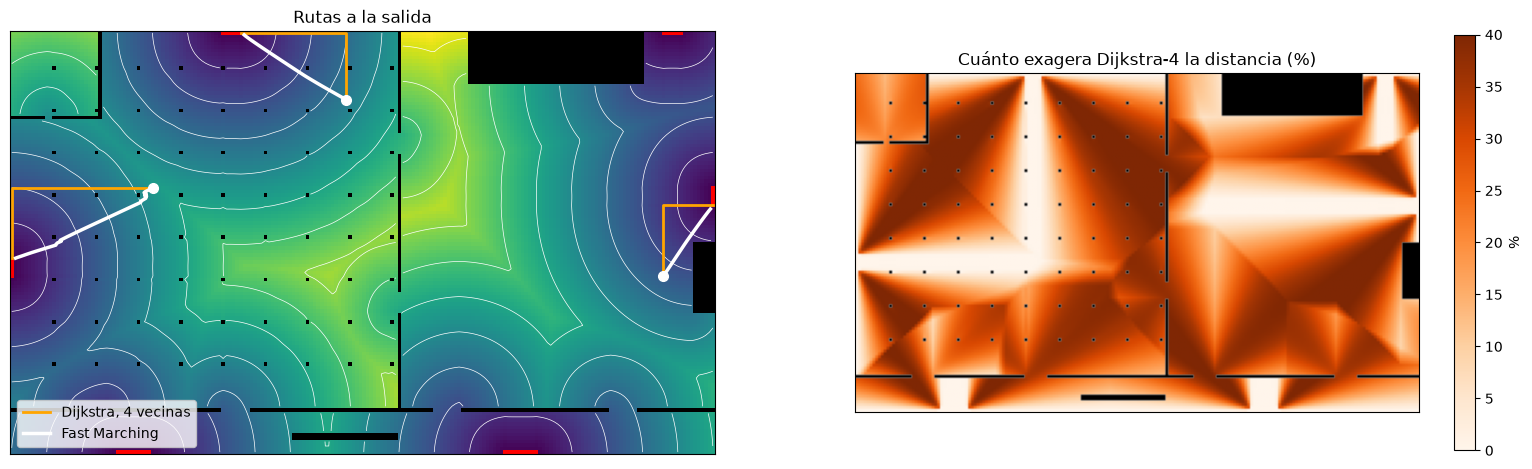

Dijkstra, 4 vecinas  exagera en promedio 24.4 %, hasta 41.5 %
Dijkstra, 8 vecinas  exagera en promedio 4.6 %, hasta 8.1 %


In [5]:
libre = ~muros
D4 = np.full((H, W), np.inf)
G4, idx4 = grafo(libre, 4)
d4, pred, _ = dijkstra(G4, directed=False, indices=idx4[salidas & libre], min_only=True,
                       return_predecessors=True)
D4[libre] = d4
D8 = dist_dijkstra(libre, salidas & libre, 8)
Dfmm = D + 0.5

def ruta_dijkstra(x, y):
    """Siguiendo a los predecesores hasta la salida."""
    yx = np.argwhere(idx4 >= 0)
    k = idx4[y, x]
    pts = [(x + 0.5, y + 0.5)]
    while pred[k] >= 0:
        k = pred[k]
        yy_, xx_ = yx[k]
        pts.append((xx_ + 0.5, yy_ + 0.5))
    return np.array(pts)

Dlleno = np.where(np.isfinite(D), D, np.nanmax(D[np.isfinite(D)]) + 20)    # muros: muy altos, para que empujen
gy, gx = np.gradient(Dlleno)

def ruta_fmm(x, y, paso=0.4):
    """Bajando por el gradiente, en continuo."""
    p = np.array([x + 0.5, y + 0.5])
    pts = [p.copy()]
    for _ in range(4000):
        coord = [[p[1] - 0.5], [p[0] - 0.5]]                        # (fila, columna) para interpolar
        g = np.array([ndimage.map_coordinates(gx, coord, order=1)[0], ndimage.map_coordinates(gy, coord, order=1)[0]])
        p = p - paso * g / (np.linalg.norm(g) + 1e-12)
        pts.append(p.copy())
        if ndimage.map_coordinates(Dlleno, [[p[1] - 0.5], [p[0] - 0.5]], order=1)[0] < 1:
            break
    return np.array(pts)

inicios = [(95, 100), (185, 50), (40, 75)]
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
mapa_distancia(ax[0], Dfmm, "Rutas a la salida", vmax=85)
for x, y in inicios:
    r1, r2 = ruta_fmm(x, y), ruta_dijkstra(x, y)
    ax[0].plot(r2[:, 0], r2[:, 1], color="orange", lw=2, label="Dijkstra, 4 vecinas" if (x, y) == inicios[0] else None)
    ax[0].plot(r1[:, 0], r1[:, 1], color="white", lw=2.5, label="Fast Marching" if (x, y) == inicios[0] else None)
    ax[0].plot(x + 0.5, y + 0.5, "o", color="white", ms=7)
ax[0].legend(loc="lower left")
dif = np.full((H, W), np.nan)
ok = np.isfinite(Dfmm)
dif[ok] = 100 * (D4[ok] - Dfmm[ok]) / np.maximum(Dfmm[ok], 1)
im = ax[1].imshow(dif, origin="lower", extent=(0, W, 0, H), cmap="Oranges", vmin=0, vmax=40)
capa(ax[1], muros, "black")
ax[1].set_title("Cuánto exagera Dijkstra-4 la distancia (%)"); ax[1].set_xticks([]); ax[1].set_yticks([])
fig.colorbar(im, ax=ax[1], shrink=0.9, label="%")
plt.show()

ok = libre & np.isfinite(Dfmm) & (Dfmm > 10)
for nombre, d in (("Dijkstra, 4 vecinas", D4), ("Dijkstra, 8 vecinas", D8)):
    e = 100 * (d[ok] - Dfmm[ok]) / Dfmm[ok]
    print("%-20s exagera en promedio %.1f %%, hasta %.1f %%" % (nombre, e.mean(), e.max()))

**Qué ver:** la ruta de Dijkstra-4 va en escuadra (en L), porque solo sabe moverse en cruz y para él todas las escuadras miden lo mismo; la de Fast Marching corta en diagonal como caminaría una persona. A la derecha, el error de Dijkstra-4 cambia de una zona a otra según la dirección hacia la salida: no es un error parejo que se cancele al comparar layouts.

## 4. ¿Cuánto cuesta?

Fast Marching funciona como Dijkstra (una fila de prioridad sobre las celdas), así que es del mismo orden, $O(N \log N)$. Aquí tarda unos milisegundos más, a cambio de dar la distancia de la ecuación continua.

In [6]:
import time

def mide(fn, veces=5):
    t0 = time.perf_counter()
    for _ in range(veces):
        fn()
    return 1000 * (time.perf_counter() - t0) / veces

print("Fast Marching:        %.1f ms" % mide(lambda: campo(salidas, muros)))
print("Dijkstra, 4 vecinas:  %.1f ms (con armar el grafo)" % mide(lambda: dist_dijkstra(libre, salidas & libre, 4)))
print("Dijkstra, 8 vecinas:  %.1f ms (con armar el grafo)" % mide(lambda: dist_dijkstra(libre, salidas & libre, 8)))
print("\nPor layout: f1 necesita una por módulo (9) y f2 una cada 2.4 s de simulación (unas 80).")

Fast Marching:        9.8 ms
Dijkstra, 4 vecinas:  2.9 ms (con armar el grafo)
Dijkstra, 8 vecinas:  5.9 ms (con armar el grafo)

Por layout: f1 necesita una por módulo (9) y f2 una cada 2.4 s de simulación (unas 80).


## Para defenderlo

- **Línea recta no:** ignora muros, y el punto es justamente medir lo que se camina.
- **Dijkstra no:** en una rejilla solo conoce 4 u 8 direcciones y exagera las distancias de forma distinta según la dirección (hasta 41 % con 4 vecinas, 8 % con 8). Eso es un sesgo de la rejilla, no del layout.
- **Fast Marching sí:** resuelve la eikonal $\|\nabla u\| = 1/v$ con error de 1 %, cuesta milisegundos como Dijkstra, y además acepta una velocidad distinta en cada celda, que es lo que necesita $f_2$ para el tiempo con multitud.

## Referencias

- Sethian, J. A. (1996). A fast marching level set method for monotonically advancing fronts. *Proceedings of the National Academy of Sciences*, 93(4), 1591–1595.
- Dijkstra, E. W. (1959). A note on two problems in connexion with graphs. *Numerische Mathematik*, 1, 269–271.